In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Load dataset
df = pd.read_csv("upi_transactions_10000.csv")

print("First 5 rows:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)

print("\nNull values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

First 5 rows:
      transaction_id            timestamp         sender_upi_id  \
0  UPI20260000001842  2026-07-01 00:14:09    priya9969@hdfcbank   
1  UPI20260000002775  2026-07-01 00:45:52       omkar1500@indus   
2  UPI20260000004709  2026-07-01 02:15:30       anjali397@icici   
3  UPI20260000002784  2026-07-01 02:15:51  rohan3038@barodampay   
4  UPI20260000006858  2026-07-01 02:41:18         sai3845@icici   

       receiver_upi_id     sender_bank   receiver_bank  amount_inr  \
0       mahesh9441@sbi       HDFC Bank             SBI      761.70   
1    jiorecharge76@sbi   IndusInd Bank             SBI      236.84   
2     nikhil2271@icici      ICICI Bank      ICICI Bank      104.00   
3        omkar7903@sbi  Bank of Baroda             SBI      635.13   
4  localkirana19@kotak      ICICI Bank  Kotak Mahindra      252.86   

  transaction_type merchant_category payment_app  ... sender_account_age_days  \
0              P2P      P2P Transfer  Google Pay  ...                    2942   


In [3]:
# Remove duplicate rows
df = df.drop_duplicates().copy()

# Convert timestamp into datetime
df["timestamp"] = pd.to_datetime(
    df["timestamp"], errors="coerce"
)

# Remove rows missing essential fields
essential_cols = [
    "transaction_id", "timestamp",
    "amount_inr", "status", "is_fraud"
]

essential_cols = [
    col for col in essential_cols if col in df.columns
]

df = df.dropna(subset=essential_cols).copy()

# Fill missing values in categorical columns
for col in df.select_dtypes(include=["object", "category"]).columns:
    if col != "transaction_id":
        df[col] = df[col].fillna("Unknown")

# Fill missing numeric values with median
for col in df.select_dtypes(include=np.number).columns:
    if col != "is_fraud":
        df[col] = df[col].fillna(df[col].median())

print("Shape after cleaning:", df.shape)
print("\nRemaining null values:")
print(df.isnull().sum())

Shape after cleaning: (10000, 25)

Remaining null values:
transaction_id             0
timestamp                  0
sender_upi_id              0
receiver_upi_id            0
sender_bank                0
receiver_bank              0
amount_inr                 0
transaction_type           0
merchant_category          0
payment_app                0
device_type                0
network_type               0
sender_city                0
sender_state               0
sender_age_group           0
sender_account_age_days    0
hour_of_day                0
day_of_week                0
is_weekend                 0
is_new_receiver            0
txn_count_last_24h         0
failed_pin_attempts        0
status                     0
failure_reason             0
is_fraud                   0
dtype: int64


In [4]:
# IQR method on transaction amount
Q1 = df["amount_inr"].quantile(0.25)
Q3 = df["amount_inr"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = max(0, Q1 - 1.5 * IQR)
upper_limit = Q3 + 1.5 * IQR

# Detect outliers
df["amount_outlier_iqr"] = (
    (df["amount_inr"] < lower_limit) |
    (df["amount_inr"] > upper_limit)
).astype(int)

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Outliers detected:", df["amount_outlier_iqr"].sum())

# Dataset with outliers removed
df_no_outliers = df[
    df["amount_outlier_iqr"] == 0
].copy()

print("Original cleaned data:", df.shape)
print("Data without outliers:", df_no_outliers.shape)

# Save both datasets
df_no_outliers.to_csv(
    "upi_transactions_cleaned_no_outliers.csv",
    index=False
)

df.to_csv(
    "upi_transactions_ml_keep_outliers.csv",
    index=False
)

Lower limit: 0
Upper limit: 1652.4225
Outliers detected: 965
Original cleaned data: (10000, 26)
Data without outliers: (9035, 26)


In [5]:
# Extract date-related features
df["date"] = df["timestamp"].dt.date
df["day"] = df["timestamp"].dt.day
df["month"] = df["timestamp"].dt.month
df["month_name"] = df["timestamp"].dt.strftime("%B")
df["year"] = df["timestamp"].dt.year
df["year_month"] = df["timestamp"].dt.to_period("M").astype(str)
df["day_name"] = df["timestamp"].dt.day_name()
df["hour"] = df["timestamp"].dt.hour

# Sort by timestamp
df = df.sort_values("timestamp")

print(df[
    ["timestamp", "day", "month", "month_name",
     "year", "day_name", "hour", "amount_inr"]
].head(10))

            timestamp  day  month month_name  year   day_name  hour  \
0 2026-07-01 00:14:09    1      7       July  2026  Wednesday     0   
1 2026-07-01 00:45:52    1      7       July  2026  Wednesday     0   
2 2026-07-01 02:15:30    1      7       July  2026  Wednesday     2   
3 2026-07-01 02:15:51    1      7       July  2026  Wednesday     2   
4 2026-07-01 02:41:18    1      7       July  2026  Wednesday     2   
5 2026-07-01 04:12:05    1      7       July  2026  Wednesday     4   
6 2026-07-01 04:17:49    1      7       July  2026  Wednesday     4   
7 2026-07-01 04:46:24    1      7       July  2026  Wednesday     4   
8 2026-07-01 05:23:32    1      7       July  2026  Wednesday     5   
9 2026-07-01 06:16:57    1      7       July  2026  Wednesday     6   

   amount_inr  
0      761.70  
1      236.84  
2      104.00  
3      635.13  
4      252.86  
5      447.09  
6      877.58  
7      198.32  
8      509.25  
9      182.92  


In [6]:
# Daily summary
daily = df.groupby("date").agg(
    transactions=("transaction_id", "count"),
    total_amount=("amount_inr", "sum"),
    average_amount=("amount_inr", "mean"),
    fraud_cases=("is_fraud", "sum")
).reset_index()

# Monthly summary
monthly = df.groupby("year_month").agg(
    transactions=("transaction_id", "count"),
    total_amount=("amount_inr", "sum"),
    average_amount=("amount_inr", "mean"),
    fraud_cases=("is_fraud", "sum")
).reset_index()

# Yearly summary
yearly = df.groupby("year").agg(
    transactions=("transaction_id", "count"),
    total_amount=("amount_inr", "sum"),
    average_amount=("amount_inr", "mean"),
    fraud_cases=("is_fraud", "sum")
).reset_index()

print("\nDAILY TRANSACTIONS")
print(daily.to_string(index=False))

print("\nMONTHLY TRANSACTIONS")
print(monthly.to_string(index=False))

print("\nYEARLY TRANSACTIONS")
print(yearly.to_string(index=False))

# Save reports in Excel
with pd.ExcelWriter("upi_transaction_reports.xlsx") as writer:
    daily.to_excel(writer, sheet_name="Daily", index=False)
    monthly.to_excel(writer, sheet_name="Monthly", index=False)
    yearly.to_excel(writer, sheet_name="Yearly", index=False)

print("\nExcel report saved successfully!")


DAILY TRANSACTIONS
      date  transactions  total_amount  average_amount  fraud_cases
2026-07-01           132      84142.25      637.441288            5
2026-07-02           108      67270.40      622.874074            4
2026-07-03           108     105390.90      975.841667            4
2026-07-04           114      80202.06      703.526842            1
2026-07-05           119     103228.26      867.464370            3
2026-07-06           112      74311.22      663.493036            4
2026-07-07           101      60445.75      598.472772            3
2026-07-08            96     117755.36     1226.618333            2
2026-07-09            91      73041.09      802.649341            4
2026-07-10           123      89803.03      730.105935            3
2026-07-11           119      71417.66      600.148403            0
2026-07-12           100      82523.16      825.231600            2
2026-07-13           115      72160.92      627.486261            0
2026-07-14           119    

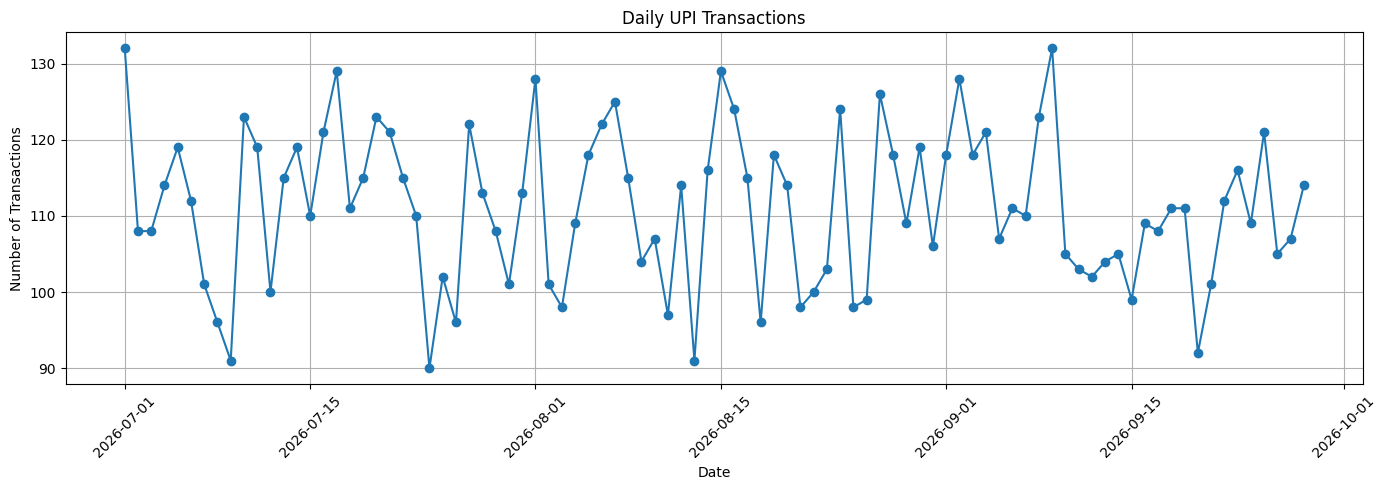

In [7]:
plt.figure(figsize=(14, 5))

plt.plot(
    pd.to_datetime(daily["date"]),
    daily["transactions"],
    marker="o"
)

plt.title("Daily UPI Transactions")
plt.xlabel("Date")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.savefig("daily_transactions.png", dpi=150)
plt.show()

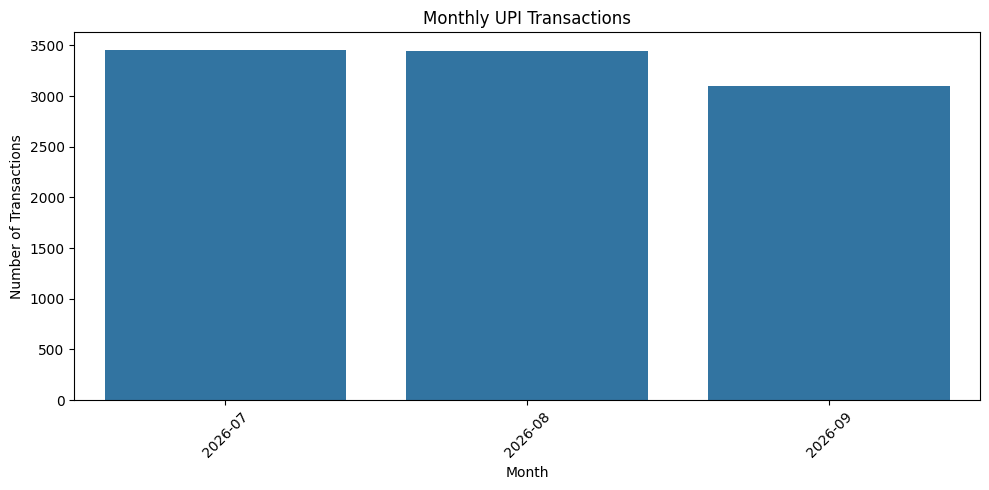

In [8]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=monthly,
    x="year_month",
    y="transactions"
)

plt.title("Monthly UPI Transactions")
plt.xlabel("Month")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("monthly_transactions.png", dpi=150)
plt.show()

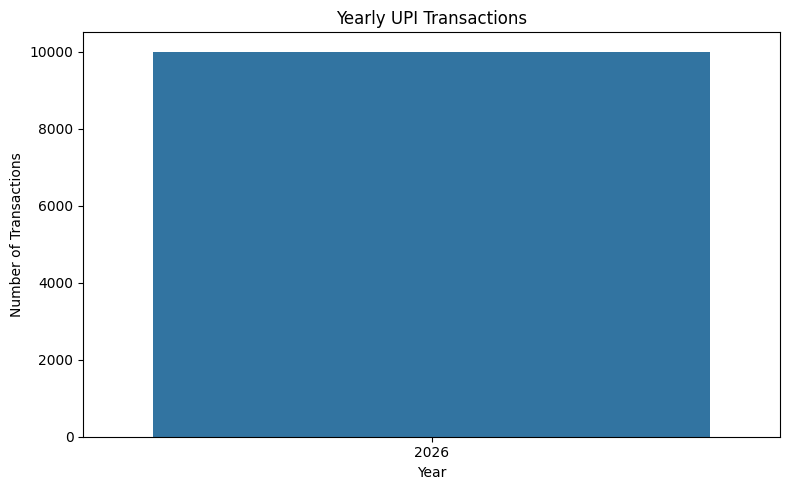

In [9]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=yearly,
    x="year",
    y="transactions"
)

plt.title("Yearly UPI Transactions")
plt.xlabel("Year")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.savefig("yearly_transactions.png", dpi=150)
plt.show()

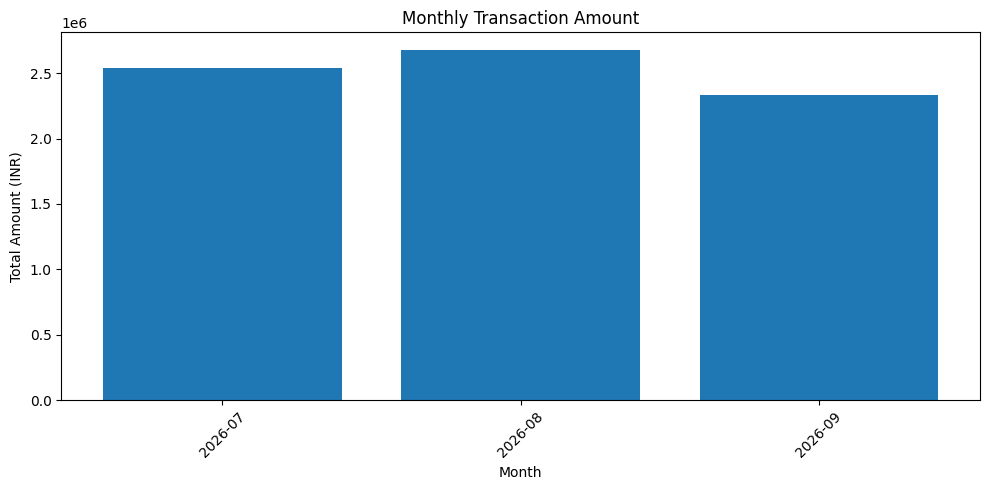

In [10]:
plt.figure(figsize=(10, 5))

plt.bar(
    monthly["year_month"],
    monthly["total_amount"]
)

plt.title("Monthly Transaction Amount")
plt.xlabel("Month")
plt.ylabel("Total Amount (INR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

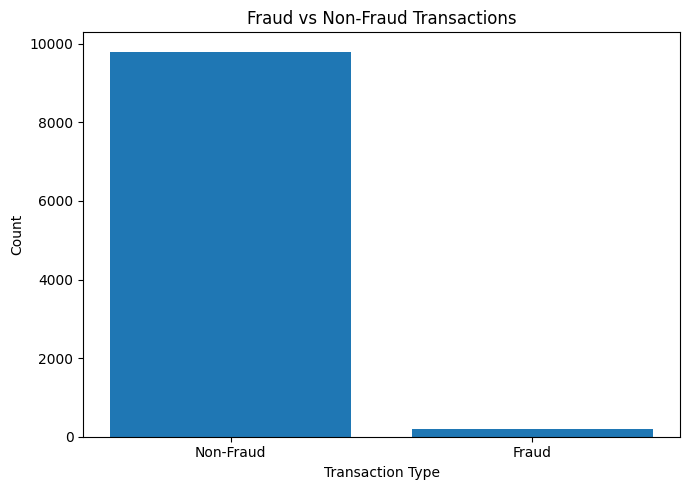

Fraud counts:
is_fraud
0    9802
1     198
Name: count, dtype: int64
Fraud percentage: 1.98 %


In [11]:
fraud_counts = df["is_fraud"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

plt.bar(
    ["Non-Fraud", "Fraud"],
    [
        fraud_counts.get(0, 0),
        fraud_counts.get(1, 0)
    ]
)

plt.title("Fraud vs Non-Fraud Transactions")
plt.xlabel("Transaction Type")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

print("Fraud counts:")
print(df["is_fraud"].value_counts())

print(
    "Fraud percentage:",
    round(df["is_fraud"].mean() * 100, 2), "%"
)

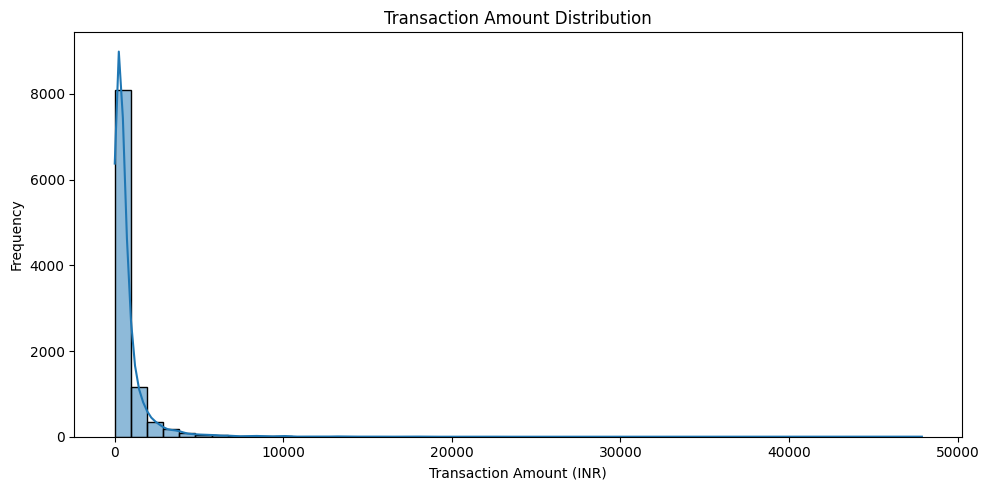

In [12]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="amount_inr",
    bins=50,
    kde=True
)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount (INR)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

           count  sum      mean  fraud_percentage
day_name                                         
Friday      1476   33  0.022358          2.235772
Monday      1452   25  0.017218          1.721763
Saturday    1452   31  0.021350          2.134986
Sunday      1395   27  0.019355          1.935484
Thursday    1424   40  0.028090          2.808989
Tuesday     1306   16  0.012251          1.225115
Wednesday   1495   26  0.017391          1.739130

Fraud by hour:
      count  sum      mean  fraud_percentage
hour                                        
0       101    2  0.019802          1.980198
1        88    7  0.079545          7.954545
2        74    7  0.094595          9.459459
3        87    4  0.045977          4.597701
4        91    6  0.065934          6.593407
5       160    3  0.018750          1.875000
6       236    6  0.025424          2.542373
7       452    9  0.019912          1.991150
8       485    7  0.014433          1.443299
9       494   10  0.020243          2.0

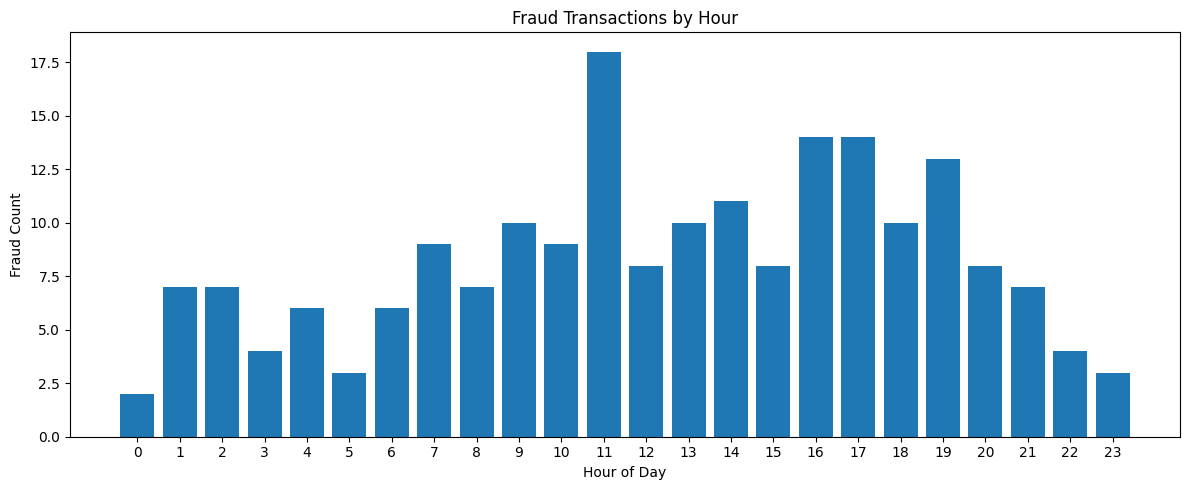

In [13]:
# Fraud cases by day of the week
fraud_by_day = df.groupby("day_name")["is_fraud"].agg(
    ["count", "sum", "mean"]
)

fraud_by_day["fraud_percentage"] = (
    fraud_by_day["mean"] * 100
)

print(fraud_by_day)

# Fraud cases by hour
fraud_by_hour = df.groupby("hour")["is_fraud"].agg(
    ["count", "sum", "mean"]
)

fraud_by_hour["fraud_percentage"] = (
    fraud_by_hour["mean"] * 100
)

print("\nFraud by hour:")
print(fraud_by_hour)

# Graph: fraud by hour
plt.figure(figsize=(12, 5))

plt.bar(
    fraud_by_hour.index,
    fraud_by_hour["sum"]
)

plt.title("Fraud Transactions by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Fraud Count")
plt.xticks(range(24))
plt.tight_layout()
plt.show()


Logistic Regression
              precision    recall  f1-score   support

           0       0.98      0.97      0.97      1960
           1       0.03      0.05      0.04        40

    accuracy                           0.95      2000
   macro avg       0.51      0.51      0.51      2000
weighted avg       0.96      0.95      0.96      2000



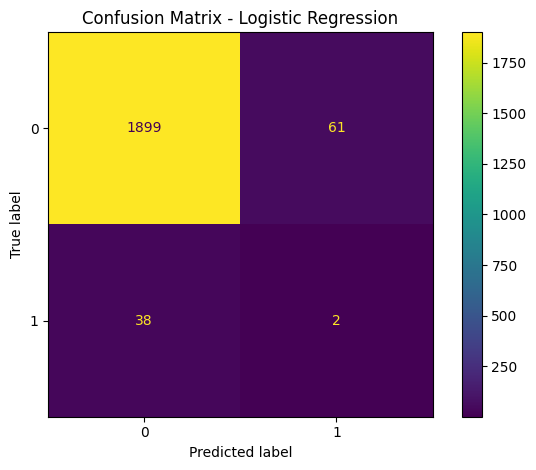


Random Forest
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1960
           1       0.00      0.00      0.00        40

    accuracy                           0.98      2000
   macro avg       0.49      0.50      0.49      2000
weighted avg       0.96      0.98      0.97      2000



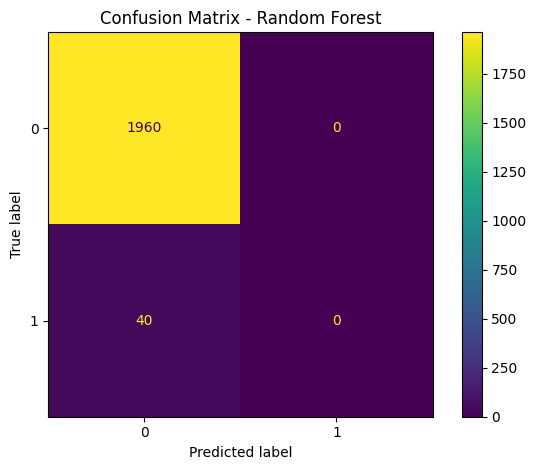


MODEL COMPARISON
              Model  Accuracy  Precision  Recall  F1 Score   PR-AUC
Logistic Regression    0.9505   0.031746    0.05  0.038835 0.053934
      Random Forest    0.9800   0.000000    0.00  0.000000 0.039531


In [14]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Create ML features
ml_df = df.copy()

# Target
y = ml_df["is_fraud"].astype(int)

# Exclude IDs, target, timestamps and possible leakage columns
exclude_cols = [
    "transaction_id",
    "timestamp",
    "date",
    "year_month",
    "month_name",
    "day_name",
    "is_fraud",
    "status",
    "failure_reason"
]

X = ml_df.drop(
    columns=[c for c in exclude_cols if c in ml_df.columns]
)

# Remove unsupported datetime columns
X = X.drop(
    columns=X.select_dtypes(
        include=["datetime", "datetimetz"]
    ).columns
)

# Convert infinity to missing
X = X.replace([np.inf, -np.inf], np.nan)

# Train-test split: stratified 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Identify numeric and categorical features
numeric_cols = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

# Preprocessing pipelines
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

# Models
models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "PR-AUC": average_precision_score(
            y_test, probabilities
        )
    })

    trained_models[name] = pipeline

    print(f"\n{name}")
    print(classification_report(
        y_test,
        predictions,
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions
    )
    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

# Compare models
results_df = pd.DataFrame(results).sort_values(
    "PR-AUC",
    ascending=False
)

print("\nMODEL COMPARISON")
print(results_df.to_string(index=False))

results_df.to_csv("model_comparison.csv", index=False)

In [15]:
import joblib

# Select the model with the highest test PR-AUC
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

joblib.dump(best_model, "best_upi_fraud_model.pkl")

print("Best model:", best_model_name)
print("Model saved successfully!")

Best model: Logistic Regression
Model saved successfully!
